# 01 · Exploration des données NASA C-MAPSS (FD001)

**Objectif du projet :** prédire la durée de vie restante (*Remaining Useful Life*, RUL) de turboréacteurs à partir de leurs capteurs, pour planifier la maintenance **avant** la panne.

**Objectif de ce notebook :** comprendre les données avant de modéliser.
1. Quelle est la structure des données ?
2. Combien de temps vivent les moteurs ?
3. Quels capteurs sont inutiles (constants) ?
4. Quels capteurs montrent la dégradation ?
5. À quoi ressemble le jeu de test ?

**Données :** FD001 = 100 moteurs d'entraînement suivis jusqu'à la panne, 100 moteurs de test arrêtés avant la panne, une seule condition de vol, un seul mode de panne (dégradation du compresseur haute pression, HPC).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import SENSOR_NAMES, SENSORS, SETTINGS, add_rul, constant_columns, load_split, load_test_rul

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
ACCENT, ALERT = "#0A6C76", "#C1621A"

## 1. Structure des données

Chaque ligne = **un moteur à un cycle donné** (un cycle ≈ un vol). Colonnes : identifiant du moteur, numéro de cycle, 3 réglages de fonctionnement, 21 capteurs.

In [2]:
train = load_split("FD001", "train")
test = load_split("FD001", "test")
rul_test = load_test_rul("FD001")

print(f"Train : {train.shape[0]:,} lignes, {train['unit'].nunique()} moteurs")
print(f"Test  : {test.shape[0]:,} lignes, {test['unit'].nunique()} moteurs")
print(f"Valeurs manquantes : {train.isna().sum().sum()}")
train.head()

Train : 20,631 lignes, 100 moteurs
Test  : 13,096 lignes, 100 moteurs
Valeurs manquantes : 0


,unit,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Durée de vie des moteurs

Dans le jeu d'entraînement, chaque moteur est suivi **jusqu'à la panne** : son dernier cycle = sa durée de vie.

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


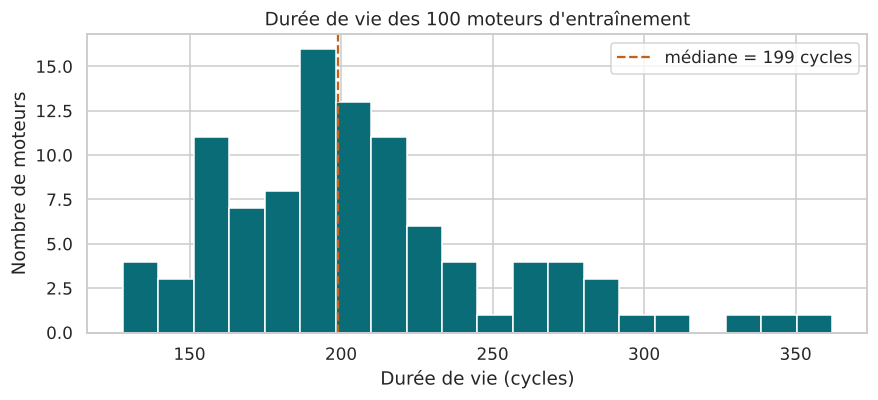

In [3]:
lifetimes = train.groupby("unit")["cycle"].max()
print(lifetimes.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(lifetimes, bins=20, color=ACCENT, edgecolor="white")
ax.axvline(lifetimes.median(), color=ALERT, ls="--", label=f"médiane = {lifetimes.median():.0f} cycles")
ax.set(xlabel="Durée de vie (cycles)", ylabel="Nombre de moteurs", title="Durée de vie des 100 moteurs d'entraînement")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "01_durees_de_vie.png"); plt.show()

**Ce que j'observe :** les durées de vie varient beaucoup (de 128 à 362 cycles, médiane ≈ 200). On ne peut donc pas prévoir la panne avec une simple règle du type « réviser au cycle 150 » : il faut lire l'**état** du moteur dans ses capteurs. C'est tout l'intérêt de la maintenance prédictive par rapport à la maintenance préventive systématique.

## 3. Calcul de la cible : la RUL

Pour chaque ligne : `RUL = dernier cycle du moteur − cycle courant`. Au dernier cycle, RUL = 0 (panne).

In [4]:
train = add_rul(train)
train[train["unit"] == 1][["unit", "cycle", "RUL"]].tail()

,unit,cycle,RUL
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


## 4. Capteurs inutiles

Un capteur qui ne varie pas ne peut rien dire sur l'usure. On regarde l'écart-type et le nombre de valeurs distinctes de chaque colonne.

In [5]:
cols = SETTINGS + SENSORS
summary = pd.DataFrame({
    "ecart_type": train[cols].std().round(4),
    "valeurs_distinctes": train[cols].nunique(),
})
summary.sort_values("ecart_type").head(10)

,ecart_type,valeurs_distinctes
s_1,0.0000,1
setting_3,0.0000,1
s_5,0.0000,1
s_10,0.0000,1
s_18,0.0000,1
s_19,0.0000,1
s_16,0.0000,1
setting_2,0.0003,13
s_6,0.0014,2
setting_1,0.0022,158


In [6]:
const_cols = constant_columns(train, cols)
# s_6 n'a que 2 valeurs distinctes (21.60 / 21.61) : arrondi d'affichage, pas un signal exploitable
quasi_const = [c for c in cols if train[c].nunique() <= 2 and c not in const_cols]
to_drop = const_cols + quasi_const
useful_sensors = [s for s in SENSORS if s not in to_drop]

print("Colonnes retirées  :", to_drop)
print(f"Capteurs conservés ({len(useful_sensors)}) :", useful_sensors)

Colonnes retirées  : ['setting_2', 'setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19', 's_6']
Capteurs conservés (14) : ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']


**Ce que j'observe :** sur FD001, il n'y a qu'**une seule condition de vol**, donc les réglages 2 et 3 et 7 capteurs (s_1, s_5, s_6, s_10, s_16, s_18, s_19) sont (quasi) constants. On garde **14 capteurs**. Sur FD002 / FD004 (6 conditions de vol), il faudra d'abord normaliser par condition, sinon ces variations masqueraient l'usure.

## 5. Comment les capteurs évoluent vers la panne

On trace chaque capteur en fonction de la **RUL** (axe inversé : la panne est à droite, à 0). Si un capteur suit une tendance nette à l'approche de la panne, il porte l'information de dégradation.

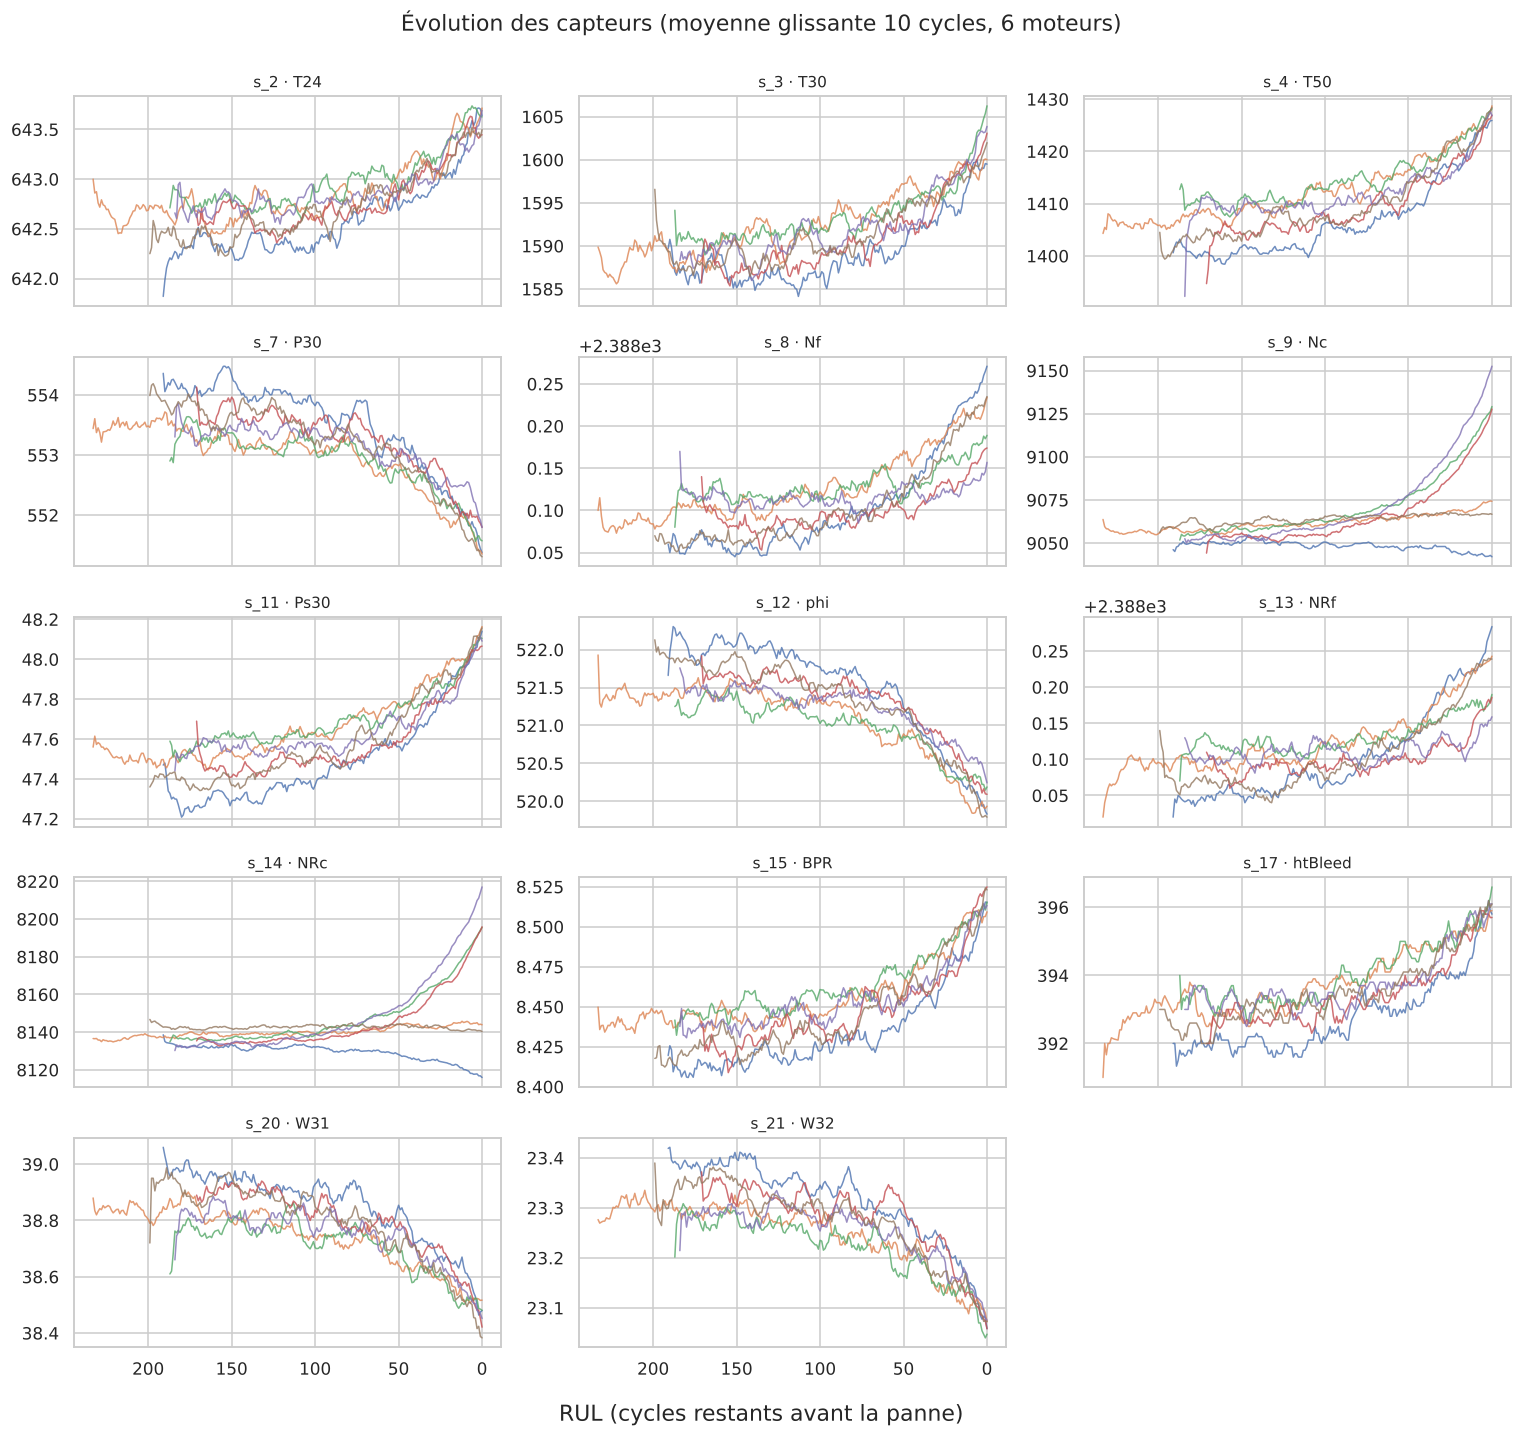

In [7]:
sample_units = [1, 20, 40, 60, 80, 100]
n = len(useful_sensors)
fig, axes = plt.subplots(int(np.ceil(n / 3)), 3, figsize=(14, 2.6 * np.ceil(n / 3)), sharex=True)
for ax, s in zip(axes.flat, useful_sensors):
    for u in sample_units:
        d = train[train["unit"] == u]
        ax.plot(d["RUL"], d[s].rolling(10, min_periods=1).mean(), lw=1, alpha=.8)
    ax.set_title(f"{s} · {SENSOR_NAMES[s].split(' - ')[0]}", fontsize=10)
axes.flat[0].invert_xaxis()  # axes partagés : une seule inversion suffit (panne à droite)
for ax in axes.flat[n:]:
    ax.remove()
fig.supxlabel("RUL (cycles restants avant la panne)")
fig.suptitle("Évolution des capteurs (moyenne glissante 10 cycles, 6 moteurs)", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "02_capteurs_vers_panne.png", bbox_inches="tight"); plt.show()

**Ce que j'observe :**
- La plupart des capteurs évoluent **lentement en début de vie**, puis la tendance **s'accélère nettement dans les ~50 derniers cycles** : la dégradation est surtout lisible en fin de vie.
- Certains **montent** vers la panne (températures s_2, s_3, s_4, pression statique s_11), d'autres **descendent** (s_7, s_12, débits de refroidissement s_20, s_21).
- s_9 et s_14 (vitesses du cœur) se comportent différemment d'un moteur à l'autre : forte hausse en fin de vie pour certains, presque plat ou même décroissant pour d'autres. À surveiller.

👉 Conséquence pour la modélisation : on **plafonnera la RUL** (≈ 125 cycles). Avant ce seuil, les capteurs ne permettent pas de distinguer un moteur à 300 cycles de vie d'un moteur à 180.

## 6. Lien entre chaque capteur et la RUL

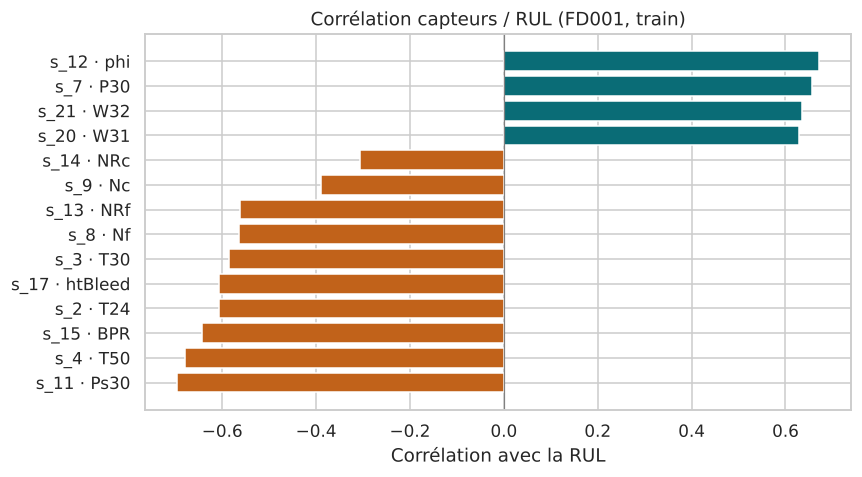

s_11   -0.70
s_4    -0.68
s_15   -0.64
s_2    -0.61
s_17   -0.61
s_3    -0.58
s_8    -0.56
s_13   -0.56
s_9    -0.39
s_14   -0.31
s_20    0.63
s_21    0.64
s_7     0.66
s_12    0.67
dtype: float64

In [8]:
corr = train[useful_sensors].corrwith(train["RUL"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = [ALERT if v < 0 else ACCENT for v in corr]
ax.barh([f"{s} · {SENSOR_NAMES[s].split(' - ')[0]}" for s in corr.index], corr.values, color=colors)
ax.axvline(0, color="grey", lw=.8)
ax.set(xlabel="Corrélation avec la RUL", title="Corrélation capteurs / RUL (FD001, train)")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_correlations_rul.png"); plt.show()
corr.round(2)

**Ce que j'observe :** s_11, s_4, s_12, s_7, s_15, s_21, s_20 sont les plus liés à la RUL (|corrélation| > 0,6). s_9 et s_14 sont plus faibles, ce qui confirme le graphique précédent. La corrélation ne mesure qu'une relation linéaire : un modèle non linéaire (Random Forest, XGBoost) pourra tirer parti de relations plus complexes.

## 7. Le jeu de test

Les moteurs de test sont **arrêtés avant la panne**. Pour chacun, on connaît sa vraie RUL à son dernier cycle observé (`RUL_FD001.txt`). C'est ce qu'on devra prédire.

       cycles_observes  RUL_reelle
count            100.0       100.0
mean             131.0        75.5
std               53.6        41.8
min               31.0         7.0
25%               88.8        32.8
50%              133.5        86.0
75%              164.2       112.2
max              303.0       145.0


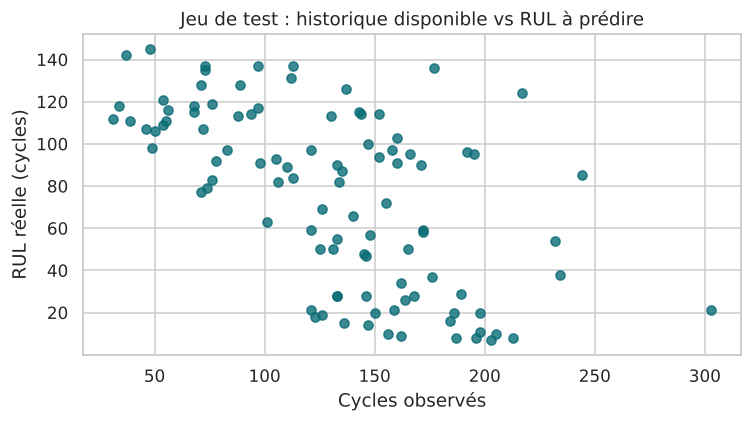

In [9]:
test_info = pd.DataFrame({
    "cycles_observes": test.groupby("unit")["cycle"].max(),
    "RUL_reelle": rul_test,
})
print(test_info.describe().round(1))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(test_info["cycles_observes"], test_info["RUL_reelle"], color=ACCENT, alpha=.8)
ax.set(xlabel="Cycles observés", ylabel="RUL réelle (cycles)", title="Jeu de test : historique disponible vs RUL à prédire")
fig.tight_layout(); fig.savefig(FIG_DIR / "04_jeu_de_test.png"); plt.show()

**Ce que j'observe :** certains moteurs de test n'ont que **31 cycles** d'historique, d'autres plus de 300. Les moteurs observés peu longtemps ont en général une grande RUL (ils sont encore jeunes) et peu de signes d'usure : ce seront les plus durs à prédire. C'est une raison de plus pour plafonner la RUL.

## 8. Conclusions et prochaines étapes

| Constat | Décision pour la suite |
|---|---|
| 9 colonnes (quasi) constantes : 2 réglages + 7 capteurs | On garde 14 capteurs |
| Dégradation visible seulement en fin de vie | RUL plafonnée à ~125 cycles |
| Signaux bruités | Lissage + indicateurs sur fenêtres glissantes (moyenne, pente, écart-type) |
| Une seule condition de vol | Normalisation simple (pas besoin de normaliser par condition sur FD001) |

**Notebook suivant → `02_features.ipynb`** : construction des indicateurs sur fenêtres glissantes et préparation des jeux train / validation.